## Dating Profile Zodiac Signs NLP Analysis
Author: Britany Goucher

Objective
Analyze dating profile descriptions grouped by astrological sign using:

Tokenization
Frequency analysis
Co-occurrence analysis
Bigram analysis
Trigram analysis
Technical Enhancement
Added trigram analysis to identify recurring three-word phrases and patterns.

In [1]:
## Python Imports


import matplotlib.pyplot as plt
import polars as pl

In [3]:
## Add CSV file

profiles_df = pl.read_csv("../Data/Dating_site.csv")

profiles_df.head()

sign,Self Description
str,str
"""gemini""","""about me: i would love to thi…"
"""cancer""","""i am a chef: this is what that…"
"""pisces""","""i'm not ashamed of much, but w…"
"""pisces""","""like everyone else on this sit…"
"""aquarius""","""hey how's it going? currently …"


In [4]:
## Frequency by Sign

sign_counts_df = profiles_df.group_by("sign").len().sort("len", descending=True)

sign_counts_df

sign,len
str,u64
"""taurus""",8
"""gemini""",8
"""pisces""",7
"""libra""",7
"""aquarius""",5
…,…
"""cancer""",4
"""leo""",4
"""aries""",1


Dataset Overview

This dataset contains 50 dating profiles categorized by astrological sign.

Profile counts vary by sign, which may affect the strength of language patterns observed during analysis.

In [6]:
## Create Corpus

corpus = []

for row in profiles_df.iter_rows(named=True):
    corpus.append({"category": row["sign"], "text": row["Self Description"]})

print(f"Corpus contains {len(corpus)} profiles.")

Corpus contains 50 profiles.


In [7]:
## Tokenization

# Stopword removal is a common preprocessing step in NLP to remove common words that may not carry significant meaning in the context of text analysis.
# The following set of stopwords is defined for this purpose.
STOPWORDS = {
    "a",
    "an",
    "and",
    "the",
    "for",
    "of",
    "to",
    "in",
    "on",
    "at",
    "with",
    "from",
    "about",
    "that",
    "this",
    "these",
    "those",
    "have",
    "has",
    "had",
    "you",
    "your",
    "you're",
    "me",
    "my",
    "myself",
    "i",
    "i'm",
    "i've",
    "i'd",
    "it",
    "it's",
    "was",
    "were",
    "are",
    "am",
    "be",
    "been",
    "being",
    "just",
    "very",
    "really",
    "like",
    "love",
    "but",
    "not",
    "can",
    "will",
    "would",
    "some",
    "more",
}


def tokenize(text: str) -> list[str]:
    """Tokenize the input text into a list of cleaned tokens."""
    tokens = text.lower().split()
    tokens = [t.strip(".,:;!?()[]\"'") for t in tokens if len(t) > 2]
    return [t for t in tokens if t not in STOPWORDS]


def tokenize_phrases(text: str) -> list[str]:
    """Tokenize text for phrase analysis without removing stopwords."""
    tokens = text.lower().split()

    return [t.strip(".,:;!?()[]\"'") for t in tokens if len(t) > 2]


# Define a new empty list to hold the token records we will create.
records_list: list[dict[str, str]] = []

# Loop through each document, tokenize the text,
# and create a record for each token with its category and
# add it to our list of records.
for doc in corpus:
    # Call our function to tokenize the text of the current document.
    tokens = tokenize(doc["text"])
    # Loop through each token produced by the tokenizer and
    # create a record that includes the category of the document and the token itself.
    # Append this record to our list of records.
    for token in tokens:
        records_list.append({"category": doc["category"], "token": token})

# Create a Polars DataFrame from the list of token records for easier analysis.
token_df: pl.DataFrame = pl.DataFrame(records_list)

# Show results
print("Tokenization complete.")
print(token_df.head(10))

Tokenization complete.
shape: (10, 2)
┌──────────┬──────────────┐
│ category ┆ token        │
│ ---      ┆ ---          │
│ str      ┆ str          │
╞══════════╪══════════════╡
│ gemini   ┆ think        │
│ gemini   ┆ kind         │
│ gemini   ┆ intellectual │
│ gemini   ┆ either       │
│ gemini   ┆ dumbest      │
│ gemini   ┆ smart        │
│ gemini   ┆ guy          │
│ gemini   ┆ smartest     │
│ gemini   ┆ dumb         │
│ gemini   ┆ guy          │
└──────────┴──────────────┘


In [8]:
## Create Token Dataframe

records_list = []

for doc in corpus:
    tokens = tokenize(doc["text"])

    for token in tokens:
        records_list.append({"category": doc["category"], "token": token})

token_df = pl.DataFrame(records_list)

token_df.head(10)

category,token
str,str
"""gemini""","""think"""
"""gemini""","""kind"""
"""gemini""","""intellectual"""
"""gemini""","""either"""
"""gemini""","""dumbest"""
"""gemini""","""smart"""
"""gemini""","""guy"""
"""gemini""","""smartest"""
"""gemini""","""dumb"""


In [9]:
## Global Frequency Analysis

global_freq_df = token_df.group_by("token").len().sort("len", descending=True)

global_freq_df.head(20)

token,len
str,u64
"""out""",39
"""people""",35
"""things""",34
"""time""",32
"""life""",30
…,…
"""when""",18
"""fun""",18
"""too""",17


In [10]:
## Category Freqencies

category_freq_df = (
    token_df.group_by(["category", "token"])
    .len()
    .sort(["category", "len"], descending=True)
)

category_freq_df.head(20)

category,token,len
str,str,u64
"""virgo""","""life""",2
"""virgo""","""when""",1
"""virgo""","""gratifying""",1
"""virgo""","""play""",1
"""virgo""","""perspective""",1
…,…,…
"""virgo""","""things""",1
"""virgo""","""gift""",1
"""taurus""","""first""",6


In [11]:
## Top Tokens Per Sign

top_per_category_dict = {}

for category in token_df["category"].unique().to_list():
    subset_df = category_freq_df.filter(pl.col("category") == category).head(10)

    top_tokens_list = subset_df["token"].to_list()

    top_per_category_dict[category] = top_tokens_list

    print(f"{category.upper()} TOP TOKENS")
    print(top_tokens_list)
    print()

CANCER TOP TOKENS
['people', 'all', 'person', 'life', 'time', 'years', 'new', 'enjoy', 'biual', 'always']

LEO TOP TOKENS
['much', 'life', 'time', 'doing', 'here', 'always', 'make', 'out', 'music', 'thing']

VIRGO TOP TOKENS
['life', 'when', 'gratifying', 'play', 'perspective', 'laugh', 'little', 'here', 'ugly', 'beauty']

GEMINI TOP TOKENS
['favorite', 'also', 'out', 'life', 'get', 'people', 'think', 'fun', 'say', 'make']

PISCES TOP TOKENS
['things', 'out', 'people', 'friends', 'now', 'also', "don't", 'most', "i'll", 'get']

ARIES TOP TOKENS
['them', 'three', 'sons', 'see', 'they', 'great', 'working', 'basketball', 'all', 'game']

SAGITTARIUS TOP TOKENS
['music', 'all', 'people', 'going', 'get', 'few', 'life', 'full-time', 'lazy', 'things']

TAURUS TOP TOKENS
['first', 'things', 'lot', 'all', 'how', 'out', 'watching', 'something', 'friends', 'around']

AQUARIUS TOP TOKENS
['time', 'city', 'friends', 'find', 'fun', 'going', 'come', 'live', 'first', 'best']

LIBRA TOP TOKENS
['here', '

In [15]:
## Bigram Analysis

bigrams_list = []

for doc in corpus:
    tokens = tokenize_phrases(doc["text"])

    for i in range(len(tokens) - 1):
        bigrams_list.append((tokens[i], tokens[i + 1]))

bigram_df = pl.DataFrame({"bigram": [f"{a} {b}" for a, b in bigrams_list]})

bigram_freq_df = bigram_df.group_by("bigram").len().sort("len", descending=True)

bigram_freq_df.head(20)

bigram,len
str,u64
"""for the""",12
"""i've been""",11
"""bay area""",9
"""and have""",9
"""and the""",9
…,…
"""i'm not""",6
"""and can""",6
"""this site""",6


In [12]:
## Technical Enhancement: Trigram Analysis

trigrams_list = []

for doc in corpus:
    tokens = tokenize_phrases(doc["text"])

    for i in range(len(tokens) - 2):
        trigrams_list.append((tokens[i], tokens[i + 1], tokens[i + 2]))

trigram_df = pl.DataFrame({"trigram": [f"{a} {b} {c}" for a, b, c in trigrams_list]})

trigram_freq_df: pl.DataFrame = (
    trigram_df.group_by("trigram")
    .len()
    .filter(pl.col("len") > 1)
    .sort(by="len", descending=True)
)

print("\nTop Trigrams:")
print(trigram_freq_df.head(20))


Top Trigrams:
shape: (20, 2)
┌──────────────────────┬─────┐
│ trigram              ┆ len │
│ ---                  ┆ --- │
│ str                  ┆ u64 │
╞══════════════════════╪═════╡
│ the bay area         ┆ 5   │
│ get along with       ┆ 4   │
│ new friends and      ┆ 3   │
│ around the world     ┆ 2   │
│ you think you        ┆ 2   │
│ …                    ┆ …   │
│ who has the          ┆ 2   │
│ being around people  ┆ 2   │
│ time for personal    ┆ 2   │
│ living san francisco ┆ 2   │
│ i'm very much        ┆ 2   │
└──────────────────────┴─────┘


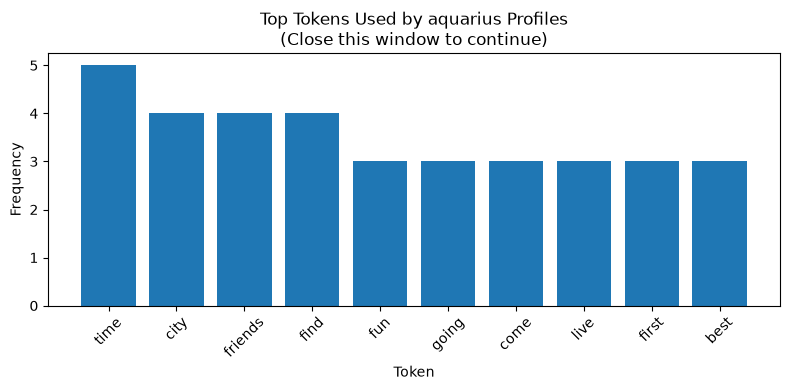

In [13]:
## Visualization: Bar Chart

# Select a zodiac sign to visualize
selected_sign = token_df["category"].unique().sort()[0]

sign_df = category_freq_df.filter(pl.col("category") == selected_sign).head(n=10)

# Create a figure that is 8 inches wide and 4 inches tall
plt.figure(figsize=(8, 4))

# Create bar chart
plt.bar(sign_df["token"], sign_df["len"])

# Rotate labels
ax = plt.gca()
ax.tick_params(axis="x", labelrotation=45)

# Titles and labels
plt.title(
    f"Top Tokens Used by {selected_sign} Profiles\n(Close this window to continue)"
)
plt.xlabel("Token")
plt.ylabel("Frequency")

# Adjust layout
plt.tight_layout()

# Show chart
plt.show()

In [16]:
## Logging Summary

print("=" * 50)
print("NLP DATING PROFILE ANALYSIS COMPLETE")
print("=" * 50)

print(f"Profiles Processed: {len(corpus)}")
print(f"Unique Signs: {profiles_df['sign'].n_unique()}")
print(f"Unique Tokens: {token_df['token'].n_unique()}")
print(f"Unique Bigrams: {bigram_df['bigram'].n_unique()}")
print(f"Unique Trigrams: {trigram_df['trigram'].n_unique()}")

print("\nTechnical Enhancement:")
print("- Trigram analysis added to identify recurring three-word phrases.")

print("\nNotebook executed successfully.")
print("=" * 50)

NLP DATING PROFILE ANALYSIS COMPLETE
Profiles Processed: 50
Unique Signs: 11
Unique Tokens: 2046
Unique Bigrams: 5398
Unique Trigrams: 5928

Technical Enhancement:
- Trigram analysis added to identify recurring three-word phrases.

Notebook executed successfully.


## Conclusions

- Stopword removal improved token frequency analysis.
- The dataset contained 50 dating profiles distributed across 11 zodiac signs.
- Bigram analysis revealed recurring profile phrases.
- Trigram analysis provided more context than unigram frequencies alone.
- Common themes included social interaction, personal interests, and location-based references.
- Due to the small dataset size, differences among zodiac signs were limited.